In [67]:
import pandas as pd
import matplotlib.pyplot as plt

In [68]:
df=pd.read_csv(r'C:\Users\user\Downloads\archive (2)\sales_data_sample.csv',encoding='unicode_escape')
df.head(3)

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium


In [69]:
print("Dataframe-in olculeri:",df.shape)
print("Dataframedeki sutunlarin data tipleri:\n",df.dtypes)

Dataframe-in olculeri: (2823, 25)
Dataframedeki sutunlarin data tipleri:
 ORDERNUMBER           int64
QUANTITYORDERED       int64
PRICEEACH           float64
ORDERLINENUMBER       int64
SALES               float64
ORDERDATE               str
STATUS                  str
QTR_ID                int64
MONTH_ID              int64
YEAR_ID               int64
PRODUCTLINE             str
MSRP                  int64
PRODUCTCODE             str
CUSTOMERNAME            str
PHONE                   str
ADDRESSLINE1            str
ADDRESSLINE2            str
CITY                    str
STATE                   str
POSTALCODE              str
COUNTRY                 str
TERRITORY               str
CONTACTLASTNAME         str
CONTACTFIRSTNAME        str
DEALSIZE                str
dtype: object


In [70]:
df['ORDERDATE']=pd.to_datetime(df['ORDERDATE'])

In [71]:
print("Dataframedeki null deyerlerin sayi(Her bir sutun uzre):\n",df.isnull().sum())
print("Dublikat deyerlerin sayi:\n",df.duplicated().sum())

Dataframedeki null deyerlerin sayi(Her bir sutun uzre):
 ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64
Dublikat deyerlerin sayi:
 0


In [72]:
df['ADDRESSLINE2']=df['ADDRESSLINE2'].fillna("unknown")
df['STATE']=df['STATE'].fillna("unknown")
df['POSTALCODE']=df['POSTALCODE'].fillna("unknown")
df['TERRITORY']=df['TERRITORY'].fillna("unknown")
print(df.isnull().sum())

ORDERNUMBER         0
QUANTITYORDERED     0
PRICEEACH           0
ORDERLINENUMBER     0
SALES               0
ORDERDATE           0
STATUS              0
QTR_ID              0
MONTH_ID            0
YEAR_ID             0
PRODUCTLINE         0
MSRP                0
PRODUCTCODE         0
CUSTOMERNAME        0
PHONE               0
ADDRESSLINE1        0
ADDRESSLINE2        0
CITY                0
STATE               0
POSTALCODE          0
COUNTRY             0
TERRITORY           0
CONTACTLASTNAME     0
CONTACTFIRSTNAME    0
DEALSIZE            0
dtype: int64


In [73]:
df['SALES'].describe().round()

count     2823.0
mean      3554.0
std       1842.0
min        482.0
25%       2203.0
50%       3185.0
75%       4508.0
max      14083.0
Name: SALES, dtype: float64

In [74]:
print(f"Status sutunu uzre unikal deyerlerin sayi:\n{df['STATUS'].value_counts()}")
print(f"\n\nProduct_line sutunu uzre unikal deyerlerin sayi:\n{df['PRODUCTLINE'].value_counts()}")
print(f"\n\nYear_id sutunu uzre unikal deyerlerin sayi:\n{df['YEAR_ID'].value_counts()}")

Status sutunu uzre unikal deyerlerin sayi:
STATUS
Shipped       2617
Cancelled       60
Resolved        47
On Hold         44
In Process      41
Disputed        14
Name: count, dtype: int64


Product_line sutunu uzre unikal deyerlerin sayi:
PRODUCTLINE
Classic Cars        967
Vintage Cars        607
Motorcycles         331
Planes              306
Trucks and Buses    301
Ships               234
Trains               77
Name: count, dtype: int64


Year_id sutunu uzre unikal deyerlerin sayi:
YEAR_ID
2004    1345
2003    1000
2005     478
Name: count, dtype: int64


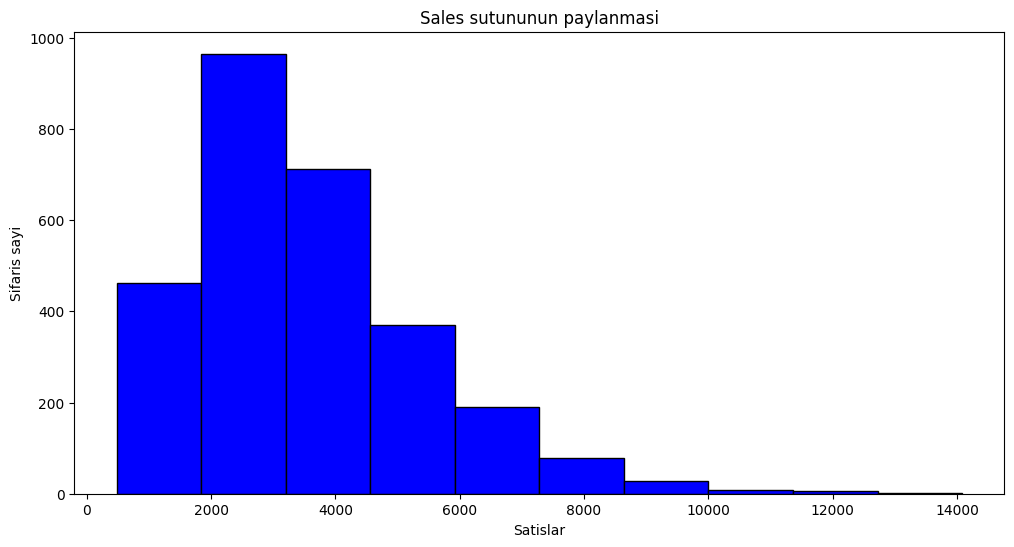

In [75]:
plt.figure(figsize=(12,6))
plt.hist(df['SALES'],bins=10,color='blue',edgecolor='black')
plt.title('Sales sutununun paylanmasi')
plt.xlabel("Satislar")
plt.ylabel("Sifaris sayi")
plt.show()

In [76]:
result=df['YEAR_ID'].value_counts().sort_values(ascending=False)
result

YEAR_ID
2004    1345
2003    1000
2005     478
Name: count, dtype: int64

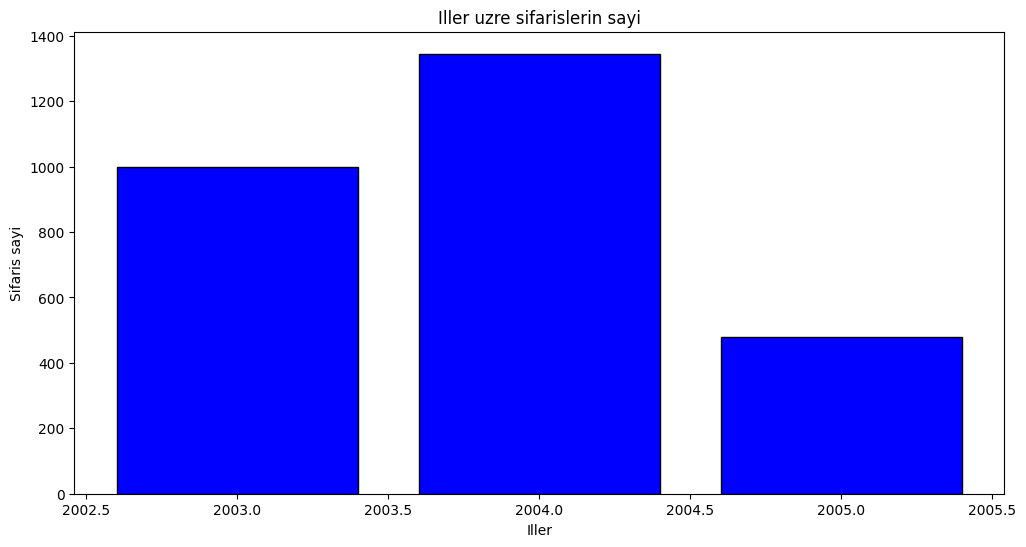

In [77]:
plt.figure(figsize=(12,6))
plt.bar(result.index,result.values,color='blue',edgecolor='black')
plt.title('Iller uzre sifarislerin sayi')
plt.xlabel("Iller")
plt.ylabel("Sifaris sayi")
plt.show()

In [78]:
barchart=df['COUNTRY'].value_counts().sort_values(ascending=False).head(5)
barchart

COUNTRY
USA          1004
Spain         342
France        314
Australia     185
UK            144
Name: count, dtype: int64

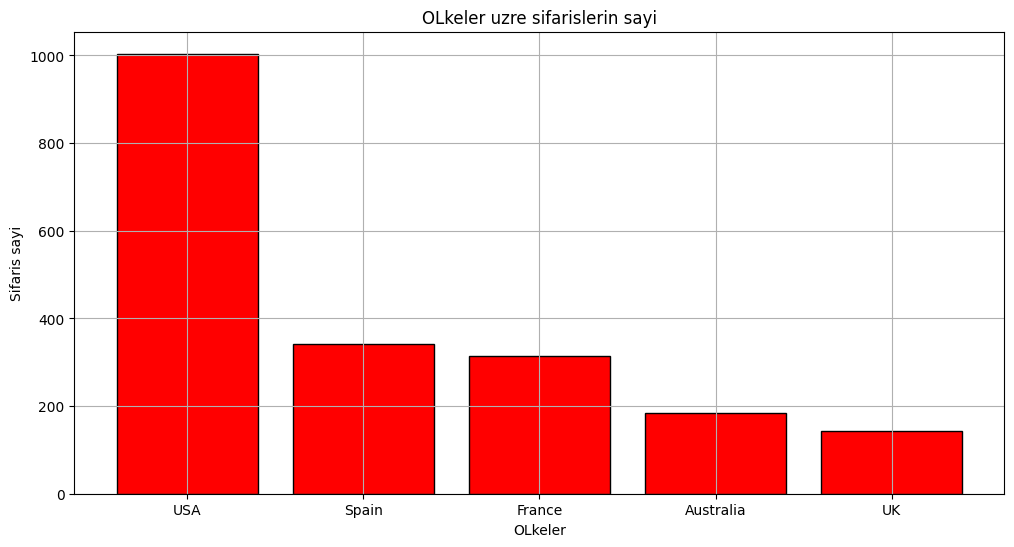

In [79]:
plt.figure(figsize=(12,6))
plt.bar(barchart.index,barchart.values,color='red',edgecolor='black')
plt.title('OLkeler uzre sifarislerin sayi')
plt.xlabel("OLkeler")
plt.ylabel("Sifaris sayi")
plt.grid(True)
plt.show()